In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import streamlit as st
import holidays

In [3]:
# Cargar los datos de ventas y competencias desde data/raw/entrenamiento
import pandas as pd

ventas_path = '../data/raw/entrenamiento/ventas.csv'
competencia_path = '../data/raw/entrenamiento/competencia.csv'
ventas_df = pd.read_csv(ventas_path)
competencia_df = pd.read_csv(competencia_path)

# Mostrar las primeras filas para verificar
print("Ventas")
print(ventas_df.head())
print("\nCompetencia")
print(competencia_df.head())

Ventas
        fecha producto_id                            nombre categoria  \
0  2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1  2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2  2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3  2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4  2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   

         subcategoria  precio_base  es_estrella  unidades_vendidas  \
0  Zapatillas Running          115         True                  6   
1  Zapatillas Running          135         True                 10   
2  Zapatillas Running           85        False                  2   
3  Zapatillas Running           75        False                  2   
4        Ropa Running           35        False                  2   

   precio_venta  ingresos  
0        118.36    710.16  
1        136.82   1368.20  
2         84.93    169.86  
3         75.42    15

In [4]:
ventas_df.head

<bound method NDFrame.head of            fecha producto_id                            nombre categoria  \
0     2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1     2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2     2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3     2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4     2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   
...          ...         ...                               ...       ...   
3547  2024-11-30    PROD_020                     Quechua MH500   Outdoor   
3548  2024-11-30    PROD_021              Manduka PRO Yoga Mat  Wellness   
3549  2024-11-30    PROD_022          Gaiam Premium Yoga Block  Wellness   
3550  2024-11-30    PROD_023                  Liforme Yoga Pad  Wellness   
3551  2024-11-30    PROD_024          Lotuscrafts Yoga Bolster  Wellness   

            subcategoria  precio_base  es_estrella  unida

In [5]:
competencia_df.head

<bound method NDFrame.head of            fecha producto_id    Amazon  Decathlon  Deporvillage
0     2021-10-25    PROD_001   82.9600     111.88       97.4300
1     2021-10-25    PROD_002  112.5600     108.61      115.5800
2     2021-10-25    PROD_003   79.7900      78.44       80.1100
3     2021-10-25    PROD_004   72.6000      67.29       74.4500
4     2021-10-25    PROD_005   37.7100      33.60       33.0700
...          ...         ...       ...        ...           ...
3547  2024-11-30    PROD_020   86.2000      72.75       82.6800
3548  2024-11-30    PROD_021  141.7125     120.60      132.1875
3549  2024-11-30    PROD_022   20.3700      17.62       20.2900
3550  2024-11-30    PROD_023   32.6400      34.06       33.2300
3551  2024-11-30    PROD_024   46.5800      45.58       50.0800

[3552 rows x 5 columns]>

In [6]:
# Convertir la columna "fecha" a tipo datetime en ambos dataframes
ventas_df['fecha'] = pd.to_datetime(ventas_df['fecha'])
competencia_df['fecha'] = pd.to_datetime(competencia_df['fecha'])

# Verificar la conevrión
print("Tipo de fecha en ventas_df:", ventas_df['fecha'].dtype)
print("Tipo de fecha en competencia_df:", competencia_df['fecha'].dtype)

Tipo de fecha en ventas_df: datetime64[us]
Tipo de fecha en competencia_df: datetime64[us]


In [7]:
ventas_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   fecha              3552 non-null   datetime64[us]
 1   producto_id        3552 non-null   str           
 2   nombre             3552 non-null   str           
 3   categoria          3552 non-null   str           
 4   subcategoria       3552 non-null   str           
 5   precio_base        3552 non-null   int64         
 6   es_estrella        3552 non-null   bool          
 7   unidades_vendidas  3552 non-null   int64         
 8   precio_venta       3552 non-null   float64       
 9   ingresos           3552 non-null   float64       
dtypes: bool(1), datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 433.1 KB


In [8]:
competencia_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3552 entries, 0 to 3551
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   fecha         3552 non-null   datetime64[us]
 1   producto_id   3552 non-null   str           
 2   Amazon        3552 non-null   float64       
 3   Decathlon     3552 non-null   float64       
 4   Deporvillage  3552 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(1)
memory usage: 166.6 KB


In [9]:
df = pd.merge(
    ventas_df,
    competencia_df,
    on=['fecha', 'producto_id'],
    how='inner'
)

df.head()

# Mostrar las primeras filas del dataframe combinado

,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07


In [10]:
# Temporary and calendar features
# Uses national Spanish holidays; regional holidays are not included.
anios = sorted(df['fecha'].dt.year.unique())
festivos_es = holidays.country_holidays('ES', years=anios)

# Date components
df['a\u00f1o'] = df['fecha'].dt.year
df['mes'] = df['fecha'].dt.month
df['dia_mes'] = df['fecha'].dt.day
df['dia_semana'] = df['fecha'].dt.dayofweek  # Monday=0, Sunday=6
df['nombre_dia_semana'] = df['dia_semana'].map({
    0: 'Lunes', 1: 'Martes', 2: 'M\u00e1rtes', 3: 'Jueves',
    4: 'Viernes', 5: 'S\u00e1bado', 6: 'Domingo'
})
df['trimestre'] = df['fecha'].dt.quarter
df['semana_iso'] = df['fecha'].dt.isocalendar().week.astype(int)
df['dia_del_a\u00f1o'] = df['fecha'].dt.dayofyear
df['semana_mes'] = ((df['dia_mes'] - 1) // 7) + 1

# Calendar flags
df['es_fin_semana'] = df['dia_semana'].isin([5, 6])
df['nombre_festivo'] = df['fecha'].dt.date.map(festivos_es)
df['es_festivo'] = df['nombre_festivo'].notna()
df['es_inicio_mes'] = df['dia_mes'] <= 3
df['es_fin_mes'] = df['fecha'].dt.is_month_end
df['es_inicio_trimestre'] = df['fecha'].dt.is_quarter_start
df['es_fin_trimestre'] = df['fecha'].dt.is_quarter_end
df['es_temporada_navidad'] = (
    ((df['mes'] == 12) & (df['dia_mes'] >= 20))
    | ((df['mes'] == 1) & (df['dia_mes'] <= 6))
)
df['es_temporada_verano'] = df['mes'].isin([6, 7, 8])

# Black Friday is the Friday after the fourth Thursday in November.
black_friday_por_anio = {}
cyber_monday_por_anio = {}
for anio in anios:
    cuarto_jueves = pd.date_range(
        start=f'{anio}-11-01', end=f'{anio}-11-30', freq='W-THU'
    )[3]
    black_friday_por_anio[anio] = cuarto_jueves + pd.Timedelta(days=1)
    cyber_monday_por_anio[anio] = black_friday_por_anio[anio] + pd.Timedelta(days=3)

fechas_normalizadas = df['fecha'].dt.normalize()
df['es_Black_Friday'] = fechas_normalizadas.isin(black_friday_por_anio.values())
df['es_cyber_Monday'] = fechas_normalizadas.isin(cyber_monday_por_anio.values())

# Cyclical encoding keeps the ends of each calendar cycle adjacent.
df['dia_semana_sin'] = np.sin(2 * np.pi * df['dia_semana'] / 7)
df['dia_semana_cos'] = np.cos(2 * np.pi * df['dia_semana'] / 7)
df['mes_sin'] = np.sin(2 * np.pi * (df['mes'] - 1) / 12)
df['mes_cos'] = np.cos(2 * np.pi * (df['mes'] - 1) / 12)

display(df[['fecha', 'a\u00f1o', 'mes', 'dia_mes', 'nombre_dia_semana', 'es_fin_semana', 'nombre_festivo', 'es_Black_Friday', 'es_cyber_Monday']].head())


C:\Users\Scarl\AppData\Local\Temp\ipykernel_21520\2352749933.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = df['fecha'].dt.dayofweek  # Monday=0, Sunday=6
C:\Users\Scarl\AppData\Local\Temp\ipykernel_21520\2352749933.py:17: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['dia_del_a\u00f1o'] = df['fecha'].dt.dayofyear


,fecha,año,mes,dia_mes,nombre_dia_semana,es_fin_semana,nombre_festivo,es_Black_Friday,es_cyber_Monday
0,2021-10-25,2021,10,25,Lunes,False,NaN,False,False
1,2021-10-25,2021,10,25,Lunes,False,NaN,False,False
2,2021-10-25,2021,10,25,Lunes,False,NaN,False,False
3,2021-10-25,2021,10,25,Lunes,False,NaN,False,False
4,2021-10-25,2021,10,25,Lunes,False,NaN,False,False


In [11]:
# Lags de ventas y media movil, calculados por producto y anio
# Se ordena cronologicamente para usar observaciones anteriores.
df = df.sort_values(['producto_id', 'fecha']).reset_index(drop=True)

columnas_lag = [f'unidades_vendidas_lag_{lag}' for lag in range(1, 8)]
grupo_anio_producto = [df['fecha'].dt.year, df['producto_id']]

for lag, columna in enumerate(columnas_lag, start=1):
    df[columna] = df.groupby(grupo_anio_producto, sort=False)['unidades_vendidas'].shift(lag)

# Usa las siete observaciones anteriores, sin incluir el dia actual.
df['media_movil_7_dias'] = df.groupby(
    grupo_anio_producto, sort=False
)['unidades_vendidas'].transform(
    lambda serie: serie.shift(1).rolling(window=7, min_periods=7).mean()
)

# Elimina filas sin historial suficiente para calcular todas las variables nuevas.
columnas_nuevas = columnas_lag + ['media_movil_7_dias']
df = df.dropna(subset=columnas_nuevas).reset_index(drop=True)

print(f'Filas restantes tras crear lags y media movil: {len(df):,}')
display(df[['fecha', 'producto_id', 'unidades_vendidas'] + columnas_nuevas].head())

Filas restantes tras crear lags y media movil: 2,880


,fecha,producto_id,unidades_vendidas,unidades_vendidas_lag_1,unidades_vendidas_lag_2,unidades_vendidas_lag_3,unidades_vendidas_lag_4,unidades_vendidas_lag_5,unidades_vendidas_lag_6,unidades_vendidas_lag_7,media_movil_7_dias
0,2021-11-01,PROD_001,7,9.0,12.0,12.0,7.0,8.0,8.0,6.0,8.857143
1,2021-11-02,PROD_001,10,7.0,9.0,12.0,12.0,7.0,8.0,8.0,9.000000
2,2021-11-03,PROD_001,11,10.0,7.0,9.0,12.0,12.0,7.0,8.0,9.285714
3,2021-11-04,PROD_001,12,11.0,10.0,7.0,9.0,12.0,12.0,7.0,9.714286
4,2021-11-05,PROD_001,10,12.0,11.0,10.0,7.0,9.0,12.0,12.0,10.428571


In [12]:
# Resumen general y calidad de datos de df
resumen_calidad = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'porcentaje_nulos': (df.isna().mean() * 100).round(2),
    'valores_unicos': df.nunique(dropna=True)
})
print(f"Dimensiones de df: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Filas completamente duplicadas: {df.duplicated().sum():,}")
print(f"Filas duplicadas por fecha y producto: {df.duplicated(subset=['fecha', 'producto_id']).sum():,}")
print(f"Rango de fechas: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
print(f"Fechas distintas: {df['fecha'].nunique():,}")
print("\nCalidad por columna:")
display(resumen_calidad)
print("Estadísticos descriptivos:")
display(df.describe(include='all').T)

Dimensiones de df: 2,880 filas x 45 columnas
Filas completamente duplicadas: 0
Filas duplicadas por fecha y producto: 0
Rango de fechas: 2021-11-01 a 2024-11-30
Fechas distintas: 120

Calidad por columna:


,tipo,nulos,porcentaje_nulos,valores_unicos
fecha,datetime64[us],0,0.00,120
producto_id,str,0,0.00,24
nombre,str,0,0.00,24
categoria,str,0,0.00,4
subcategoria,str,0,0.00,16
precio_base,int64,0,0.00,21
es_estrella,bool,0,0.00,2
unidades_vendidas,int64,0,0.00,52
precio_venta,float64,0,0.00,2081
ingresos,float64,0,0.00,2477


Estadísticos descriptivos:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,2880,NaN,NaN,NaN,2023-05-17 06:00:00,2021-11-01 00:00:00,2022-08-09 00:00:00,2023-05-17 00:00:00,2024-02-22 06:00:00,2024-11-30 00:00:00,NaN
producto_id,2880,24,PROD_001,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre,2880,24,Nike Air Zoom Pegasus 40,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categoria,2880,4,Running,960,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategoria,2880,16,Zapatillas Running,720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio_base,2880.0,NaN,NaN,NaN,123.125,20.0,48.75,72.5,118.75,830.0,165.582193
es_estrella,2880,2,False,2040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unidades_vendidas,2880.0,NaN,NaN,NaN,5.257292,1.0,2.0,3.0,5.0,85.0,6.807285
precio_venta,2880.0,NaN,NaN,NaN,121.457628,19.0,47.2025,71.81,118.0725,854.15,163.523608
ingresos,2880.0,NaN,NaN,NaN,647.654191,19.46,134.805,221.515,663.0,14508.4,1156.424021


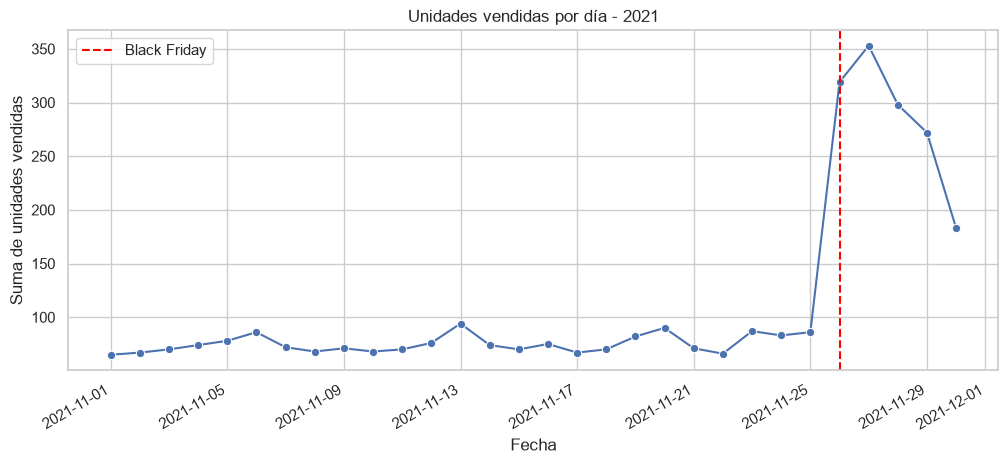

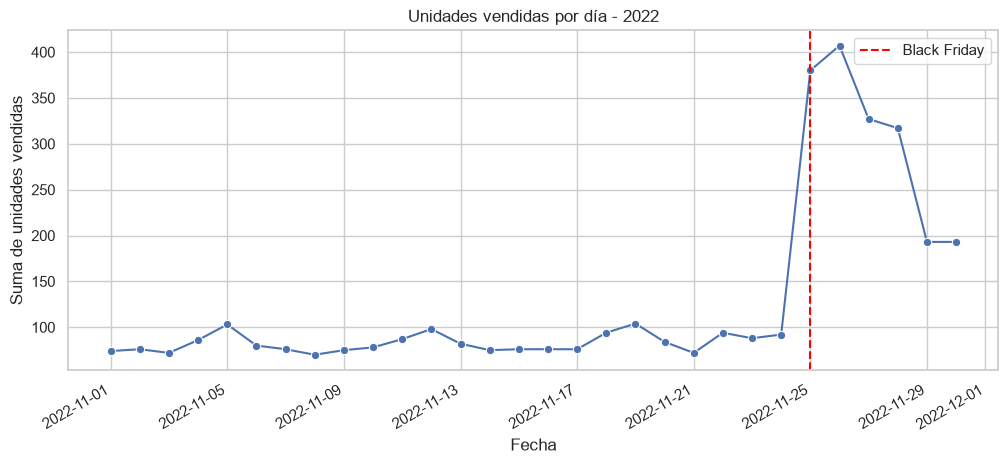

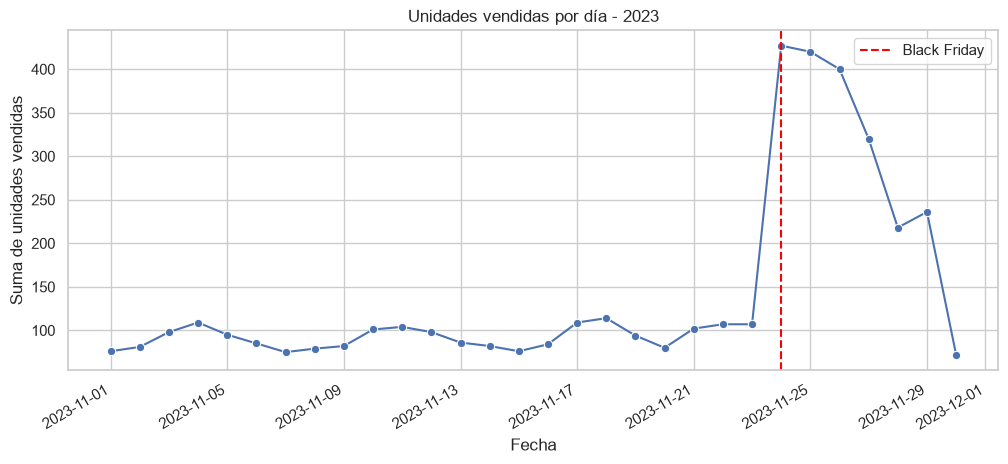

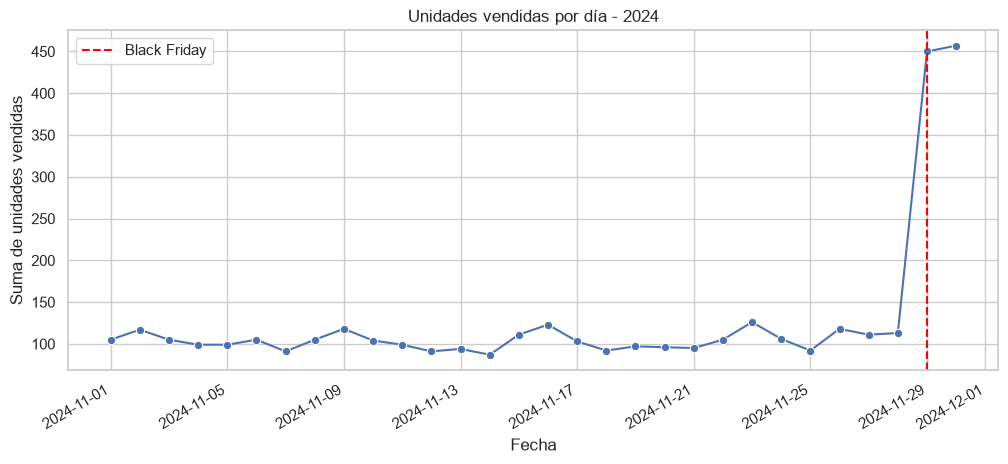

In [13]:
# Serie temporal diaria de unidades vendidas: un gráfico por anio
sns.set_theme(style='whitegrid')
unidades_por_fecha = (
    df.groupby('fecha', as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('fecha')
)

for anio in sorted(df['fecha'].dt.year.unique()):
    unidades_anio = unidades_por_fecha[unidades_por_fecha['fecha'].dt.year == anio]
    figura, eje = plt.subplots(figsize=(12, 5))
    sns.lineplot(
        data=unidades_anio,
        x='fecha',
        y='unidades_vendidas',
        marker='o',
        ax=eje
    )
    black_friday = black_friday_por_anio[anio]
    if unidades_anio['fecha'].min() <= black_friday <= unidades_anio['fecha'].max():
        eje.axvline(black_friday, color='red', linestyle='--', label='Black Friday')
        eje.legend()
    eje.set(
        title=f'Unidades vendidas por día - {anio}',
        xlabel='Fecha',
        ylabel='Suma de unidades vendidas'
    )
    figura.autofmt_xdate()
    plt.show()

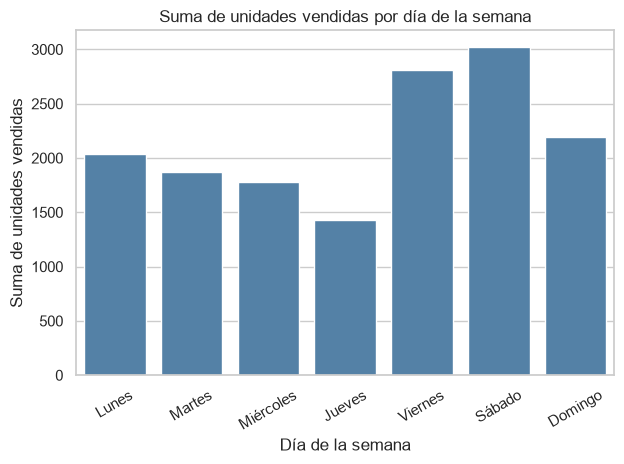

In [14]:
# Suma de unidades vendidas por día de la semana
dias_semana = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
unidades_por_dia = (
    df.assign(dia_semana=df['fecha'].dt.day_of_week.map(dict(enumerate(dias_semana))))
    .groupby('dia_semana', as_index=False)['unidades_vendidas']
    .sum()
)
sns.barplot(
    data=unidades_por_dia,
    x='dia_semana',
    y='unidades_vendidas',
    order=dias_semana,
    color='steelblue'
)
plt.title('Suma de unidades vendidas por día de la semana')
plt.xlabel('Día de la semana')
plt.ylabel('Suma de unidades vendidas')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

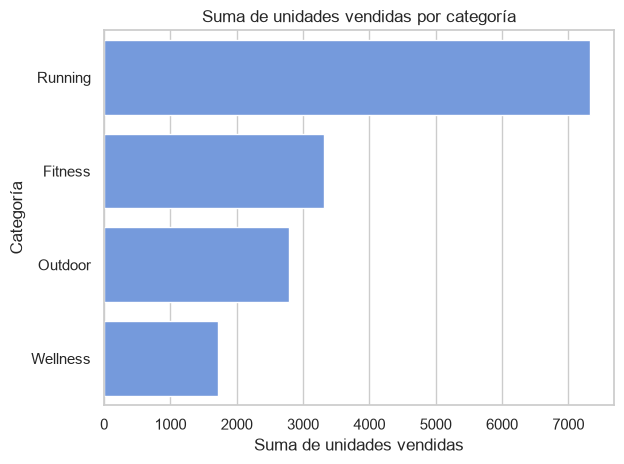

In [15]:
# Suma de unidades vendidas por categoría
unidades_por_categoria = (
    df.groupby('categoria', as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('unidades_vendidas', ascending=False)
)
sns.barplot(
    data=unidades_por_categoria,
    y='categoria',
    x='unidades_vendidas',
    color='cornflowerblue'
)
plt.title('Suma de unidades vendidas por categoría')
plt.xlabel('Suma de unidades vendidas')
plt.ylabel('Categoría')
plt.tight_layout()
plt.show()

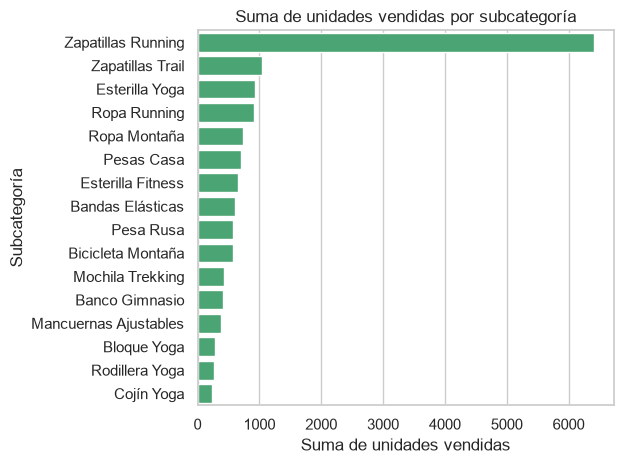

In [16]:
# Suma de unidades vendidas por subcategoría
unidades_por_subcategoria = (
    df.groupby('subcategoria', as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('unidades_vendidas', ascending=False)
)
sns.barplot(
    data=unidades_por_subcategoria,
    y='subcategoria',
    x='unidades_vendidas',
    color='mediumseagreen'
)
plt.title('Suma de unidades vendidas por subcategoría')
plt.xlabel('Suma de unidades vendidas')
plt.ylabel('Subcategoría')
plt.tight_layout()
plt.show()

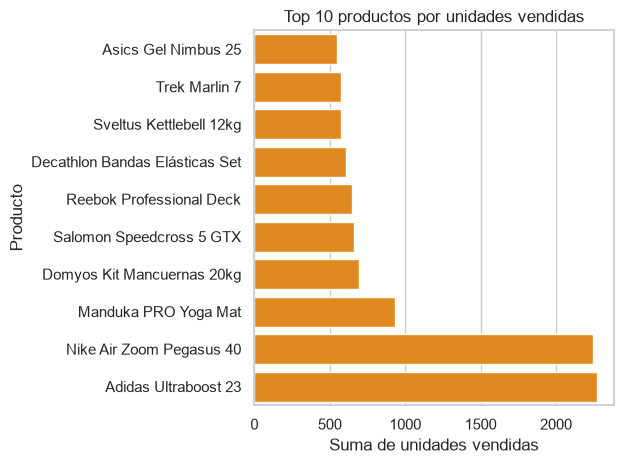

,producto_id,nombre,unidades_vendidas
2,PROD_003,Asics Gel Nimbus 25,549
15,PROD_016,Trek Marlin 7,571
13,PROD_014,Sveltus Kettlebell 12kg,576
12,PROD_013,Decathlon Bandas Elásticas Set,608
10,PROD_011,Reebok Professional Deck,648
14,PROD_015,Salomon Speedcross 5 GTX,660
11,PROD_012,Domyos Kit Mancuernas 20kg,696
20,PROD_021,Manduka PRO Yoga Mat,933
0,PROD_001,Nike Air Zoom Pegasus 40,2248
1,PROD_002,Adidas Ultraboost 23,2271


In [17]:
# Top 10 productos por suma de unidades vendidas
top_productos = (
    df.groupby(['producto_id', 'nombre'], as_index=False)['unidades_vendidas']
    .sum()
    .nlargest(10, 'unidades_vendidas')
    .sort_values('unidades_vendidas', ascending=True)
)
sns.barplot(
    data=top_productos,
    y='nombre',
    x='unidades_vendidas',
    color='darkorange'
)
plt.title('Top 10 productos por unidades vendidas')
plt.xlabel('Suma de unidades vendidas')
plt.ylabel('Producto')
plt.tight_layout()
plt.show()
display(top_productos)

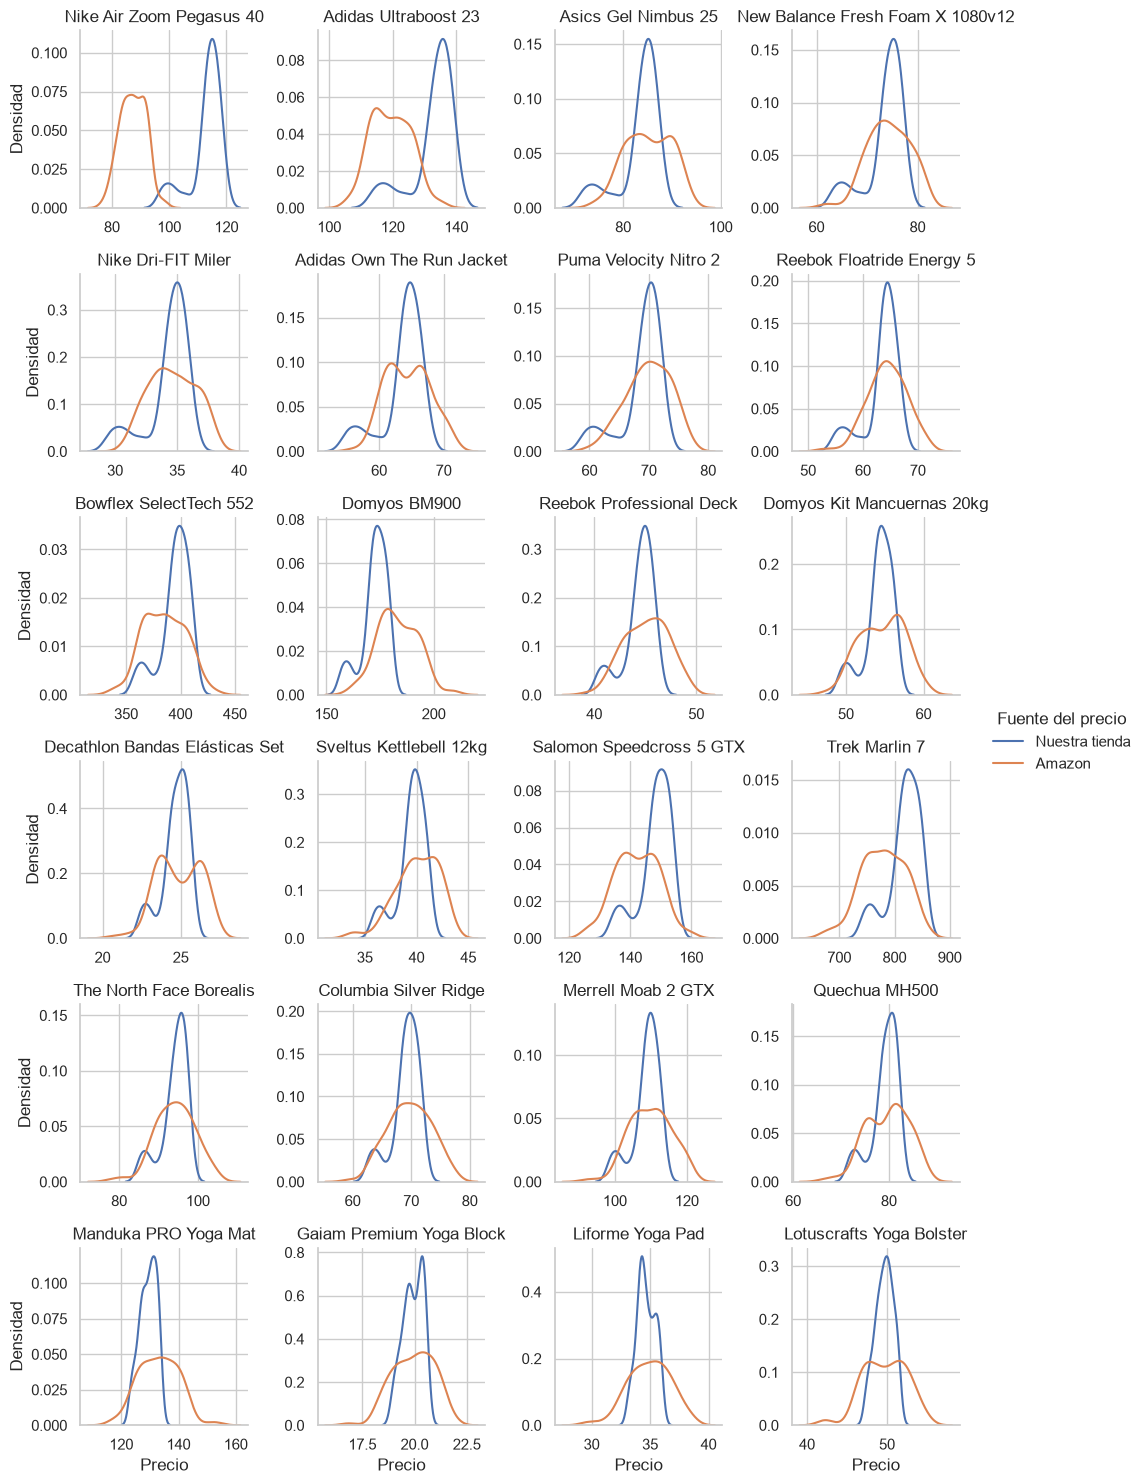

In [18]:
# Densidad de precios propios y de Amazon, comparados por producto
precios_por_producto = df.melt(
    id_vars=['producto_id', 'nombre'],
    value_vars=['precio_venta', 'Amazon'],
    var_name='fuente',
    value_name='precio'
)
precios_por_producto['fuente'] = precios_por_producto['fuente'].map({
    'precio_venta': 'Nuestra tienda',
    'Amazon': 'Amazon'
})
figura_precios = sns.FacetGrid(
    precios_por_producto,
    col='nombre',
    col_wrap=4,
    hue='fuente',
    sharex=False,
    sharey=False,
    height=2.5
)
figura_precios.map_dataframe(
    sns.kdeplot,
    x='precio',
    fill=False,
    common_norm=False
)
figura_precios.add_legend(title='Fuente del precio')
figura_precios.set_axis_labels('Precio', 'Densidad')
figura_precios.set_titles('{col_name}')
figura_precios.tight_layout()
plt.show()

In [19]:
# Crear lags y media móvil por producto y año calendario.
ventas_df = ventas_df.sort_values(["producto_id", "fecha"]).copy()
ventas_df["_anio"] = ventas_df["fecha"].dt.year

for lag in range(1, 8):
    ventas_df[f"unidades_vendidas_lag_{lag}"] = (
        ventas_df.groupby(["producto_id", "_anio"])["unidades_vendidas"].shift(lag)
    )

# La media usa las siete observaciones anteriores, sin incluir el día actual.
ventas_df["media_movil_7_dias"] = (
    ventas_df.groupby(["producto_id", "_anio"])["unidades_vendidas"]
    .transform(lambda serie: serie.shift(1).rolling(window=7, min_periods=7).mean())
)

columnas_nuevas = [
    f"unidades_vendidas_lag_{lag}" for lag in range(1, 8)
] + ["media_movil_7_dias"]


In [20]:
filas_antes = len(ventas_df)
ventas_df = ventas_df.dropna(subset=columnas_nuevas).drop(columns=["_anio"])
ventas_df["descuento_porcentaje"] = (
    (ventas_df["precio_venta"] - ventas_df["precio_base"])
    / ventas_df["precio_base"]
) * 100
ventas_df = ventas_df.sort_values(["fecha", "producto_id"]).reset_index(drop=True)

print(f"Filas eliminadas por nulos en variables nuevas: {filas_antes - len(ventas_df)}")
print(ventas_df[["fecha", "producto_id", "unidades_vendidas", "descuento_porcentaje"] + columnas_nuevas].head())

Filas eliminadas por nulos en variables nuevas: 672
       fecha producto_id  unidades_vendidas  descuento_porcentaje  \
0 2021-11-01    PROD_001                  7              0.060870   
1 2021-11-01    PROD_002                 10              0.740741   
2 2021-11-01    PROD_003                  2              0.164706   
3 2021-11-01    PROD_004                  2              2.320000   
4 2021-11-01    PROD_005                  2             -0.314286   

   unidades_vendidas_lag_1  unidades_vendidas_lag_2  unidades_vendidas_lag_3  \
0                      9.0                     12.0                     12.0   
1                     10.0                     12.0                      9.0   
2                      3.0                      3.0                      3.0   
3                      3.0                      3.0                      2.0   
4                      2.0                      2.0                      2.0   

   unidades_vendidas_lag_4  unidades_vendidas_lag_5 

In [21]:
# Promedio de precios de competencia y ratio frente a nuestro precio.
df = pd.merge(
    ventas_df,
    competencia_df,
    on=["fecha", "producto_id"],
    how="inner"
)

columnas_competencia = ["Amazon", "Decathlon", "Deporvillage"]
df["precio_competencia"] = df[columnas_competencia].mean(axis=1)
df["ratio_precio"] = df["precio_venta"] / df["precio_competencia"]
df = df.drop(columns=columnas_competencia)

display(df[["fecha", "producto_id", "precio_venta", "precio_competencia", "ratio_precio"]].head())

,fecha,producto_id,precio_venta,precio_competencia,ratio_precio
0,2021-11-01,PROD_001,115.07,95.353333,1.206775
1,2021-11-01,PROD_002,136.00,113.393333,1.199365
2,2021-11-01,PROD_003,85.14,83.276667,1.022375
3,2021-11-01,PROD_004,76.74,71.843333,1.068158
4,2021-11-01,PROD_005,34.89,33.490000,1.041804


In [22]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   fecha                    2880 non-null   datetime64[us]
 1   producto_id              2880 non-null   str           
 2   nombre                   2880 non-null   str           
 3   categoria                2880 non-null   str           
 4   subcategoria             2880 non-null   str           
 5   precio_base              2880 non-null   int64         
 6   es_estrella              2880 non-null   bool          
 7   unidades_vendidas        2880 non-null   int64         
 8   precio_venta             2880 non-null   float64       
 9   ingresos                 2880 non-null   float64       
 10  unidades_vendidas_lag_1  2880 non-null   float64       
 11  unidades_vendidas_lag_2  2880 non-null   float64       
 12  unidades_vendidas_lag_3  2880 non-null   floa

In [23]:
# Crear copias categóricas con sufijo _h y aplicar one-hot encoding.
df["nombre_h"] = df["nombre"]
df["categoria_h"] = df["categoria"]
df["subcategoria_h"] = df["subcategoria"]

#One hot encoding sobre nombre_h, categoria_h y subcategoria_h. 
df = pd.get_dummies(
    df,
    columns=["nombre_h", "categoria_h", "subcategoria_h"],
    drop_first=False
)

# Mostrar primeras filas
df.head()

,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,...,subcategoria_h_Esterilla Yoga,subcategoria_h_Mancuernas Ajustables,subcategoria_h_Mochila Trekking,subcategoria_h_Pesa Rusa,subcategoria_h_Pesas Casa,subcategoria_h_Rodillera Yoga,subcategoria_h_Ropa Montaña,subcategoria_h_Ropa Running,subcategoria_h_Zapatillas Running,subcategoria_h_Zapatillas Trail
0,2021-11-01,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,7,115.07,805.49,...,False,False,False,False,False,False,False,False,True,False
1,2021-11-01,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.00,1360.00,...,False,False,False,False,False,False,False,False,True,False
2,2021-11-01,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,85.14,170.28,...,False,False,False,False,False,False,False,False,True,False
3,2021-11-01,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,76.74,153.48,...,False,False,False,False,False,False,False,False,True,False
4,2021-11-01,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,34.89,69.78,...,False,False,False,False,False,False,False,True,False,False


In [24]:
# Guardar el dataframe procesado en formato CSV.
df.to_csv("../data/processed/df.csv", index=False)
print("DataFrame guardado en ../data/processed/df.csv")

DataFrame guardado en ../data/processed/df.csv


In [25]:
ventas_df['fecha'] = pd.to_datetime(ventas_df['fecha'])

# Dividir el dataframe en train y validation según el año
train_df = ventas_df[ventas_df['fecha'].dt.year.between(2021, 2023)].copy()
validation_df = ventas_df[ventas_df['fecha'].dt.year == 2024].copy()

# Mostarr la cantidad de registros
print(f'Registros en train_df: {len(train_df)}')
print(f'Registros en validation_df: {len(validation_df)}')

Registros en train_df: 2160
Registros en validation_df: 720


In [26]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = 'unidades_vendidas'
columnas_excluidas = {'fecha', 'ingresos', target}
columnas_object = set(train_df.select_dtypes(include=['object']).columns)

predictoras = [
    columna for columna in train_df.columns
    if columna not in columnas_excluidas
    and columna not in columnas_object
]

train_modelo = train_df.dropna(subset=[target])
validation_modelo = validation_df.dropna(subset=[target])

X_train = train_modelo[predictoras]
y_train = train_modelo[target]
X_validation = validation_modelo[predictoras]
y_validation = validation_modelo[target]

modelo = HistGradientBoostingRegressor(
    learning_rate=0.03,
    max_iter=500,
    max_depth=5,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

modelo.fit(X_train, y_train)

prediccion_modelo = modelo.predict(X_validation)
prediccion_naive = np.full(len(y_validation), y_train.mean())

def calcular_metricas(y_real, y_predicho):
    y_real = np.asarray(y_real)
    y_predicho = np.asarray(y_predicho)

    mascara_mape = y_real != 0
    denominador_smape = np.abs(y_real) + np.abs(y_predicho)
    smape = np.divide(
        200 * np.abs(y_real - y_predicho),
        denominador_smape,
        out=np.zeros_like(y_real, dtype=float),
        where=denominador_smape != 0
    ).mean()

    suma_real = np.abs(y_real).sum()

    return {
        'MAE': mean_absolute_error(y_real, y_predicho),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_predicho)),
        'MAPE (%)': (
            np.abs((y_real[mascara_mape] - y_predicho[mascara_mape])
                   / y_real[mascara_mape]).mean() * 100
            if mascara_mape.any() else np.nan
        ),
        'sMAPE (%)': smape,
        'WAPE (%)': (
            np.abs(y_real - y_predicho).sum() / suma_real * 100
            if suma_real != 0 else np.nan
        ),
        'R2': r2_score(y_real, y_predicho)
    }

resultados = pd.DataFrame(
    {
        'HistGradientBoostingRegressor': calcular_metricas(
            y_validation, prediccion_modelo
        ),
        'Baseline (media)': calcular_metricas(
            y_validation, prediccion_naive
        )
    }
).T

print(f'Registros de entrenamiento usados: {len(y_train)}')
print(f'Registros de validación evaluados: {len(y_validation)}')
print(f'Predictoras usadas: {predictoras}')
display(resultados)


C:\Users\Scarl\AppData\Local\Temp\ipykernel_21520\2191416921.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_object = set(train_df.select_dtypes(include=['object']).columns)


Registros de entrenamiento usados: 2160
Registros de validación evaluados: 720
Predictoras usadas: ['precio_base', 'es_estrella', 'precio_venta', 'unidades_vendidas_lag_1', 'unidades_vendidas_lag_2', 'unidades_vendidas_lag_3', 'unidades_vendidas_lag_4', 'unidades_vendidas_lag_5', 'unidades_vendidas_lag_6', 'unidades_vendidas_lag_7', 'media_movil_7_dias', 'descuento_porcentaje']


,MAE,RMSE,MAPE (%),sMAPE (%),WAPE (%),R2
HistGradientBoostingRegressor,0.938266,1.893936,19.214717,18.176994,17.712419,0.919904
Baseline (media),3.669289,6.692288,93.021778,62.612082,69.268169,-0.000063


,fecha,producto_id,nombre,unidades_vendidas,unidades_predichas
2161,2024-11-01,PROD_002,Adidas Ultraboost 23,19,17.315477
2185,2024-11-02,PROD_002,Adidas Ultraboost 23,16,15.842962
2209,2024-11-03,PROD_002,Adidas Ultraboost 23,18,13.665676
2233,2024-11-04,PROD_002,Adidas Ultraboost 23,16,18.069168
2257,2024-11-05,PROD_002,Adidas Ultraboost 23,18,19.153227
...,...,...,...,...,...
2775,2024-11-26,PROD_016,Trek Marlin 7,4,4.501229
2799,2024-11-27,PROD_016,Trek Marlin 7,4,3.975228
2823,2024-11-28,PROD_016,Trek Marlin 7,5,4.127876
2847,2024-11-29,PROD_016,Trek Marlin 7,16,16.322774


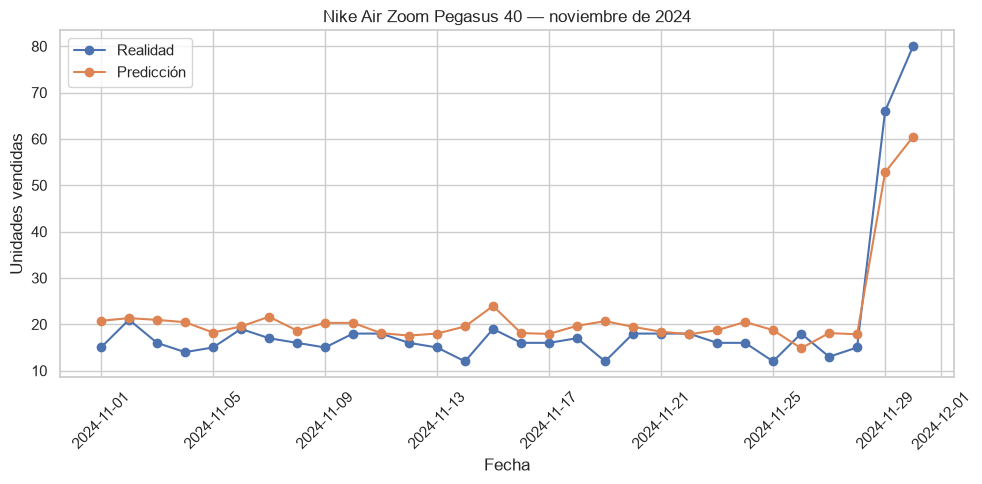

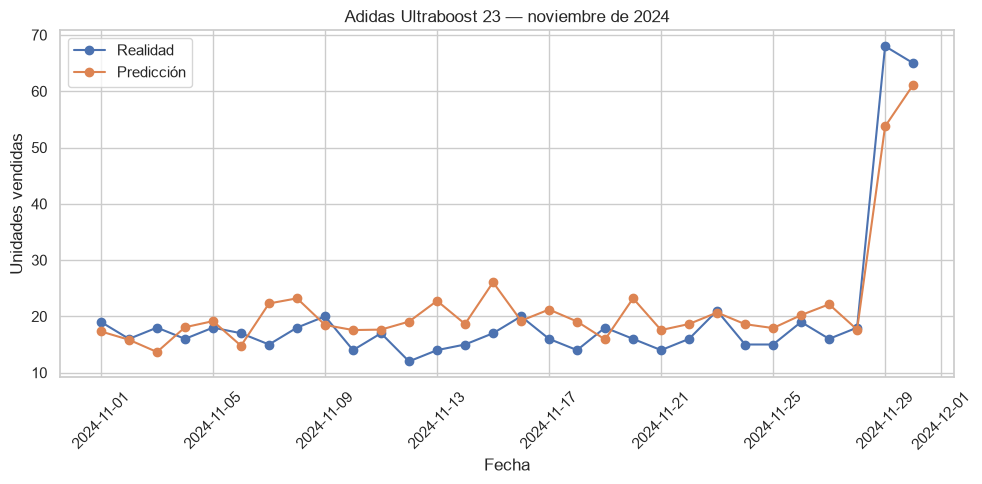

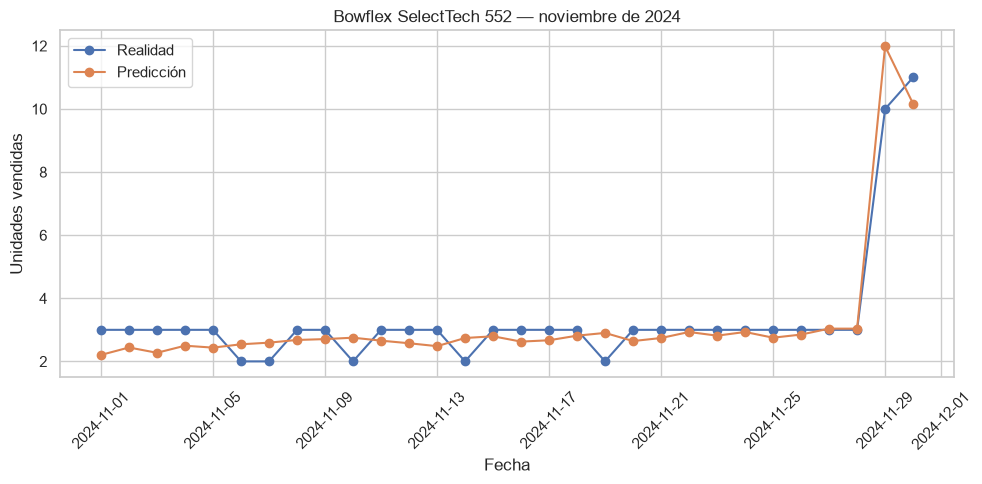

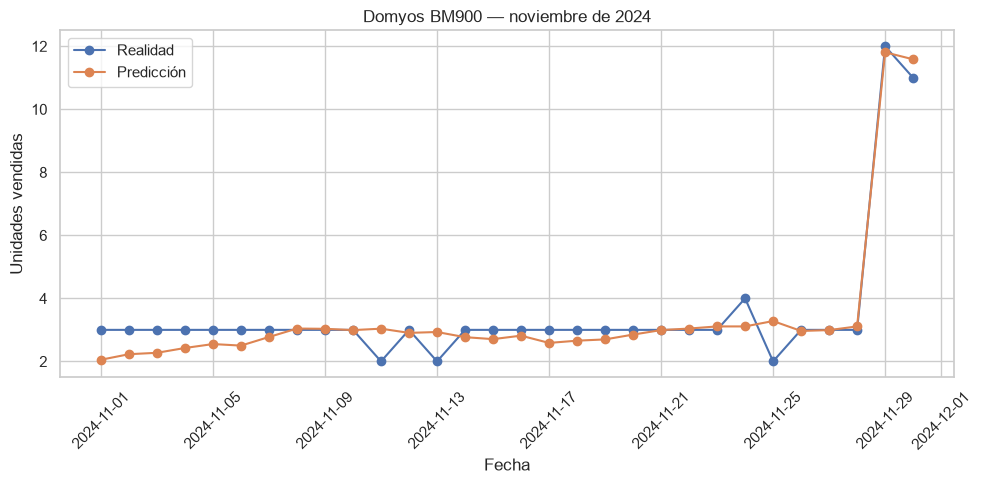

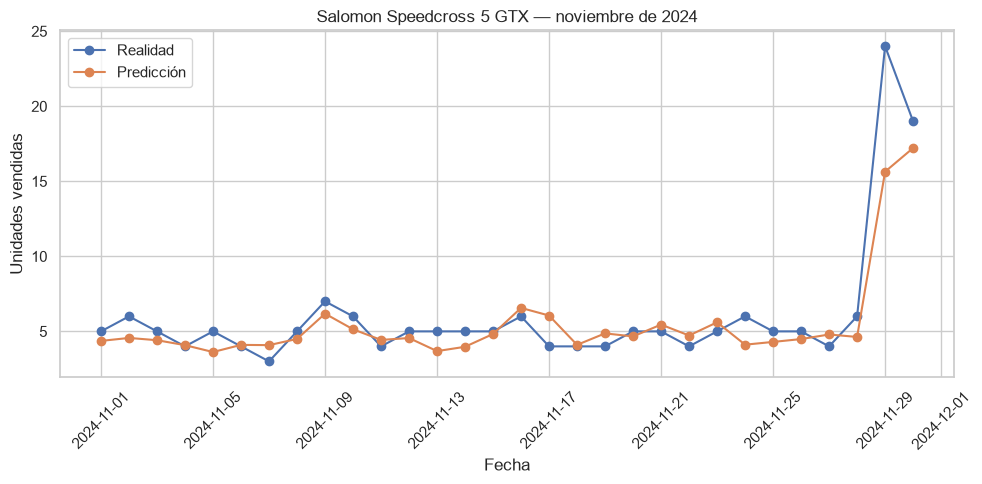

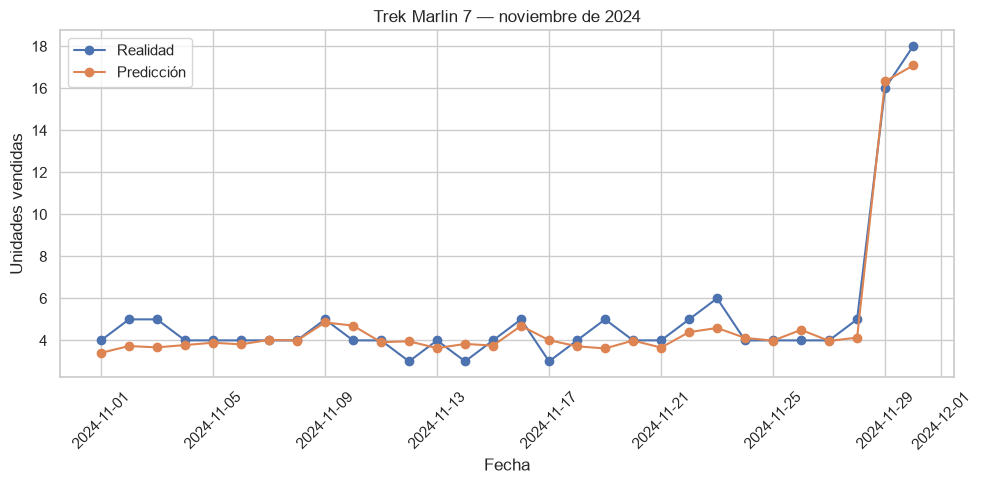

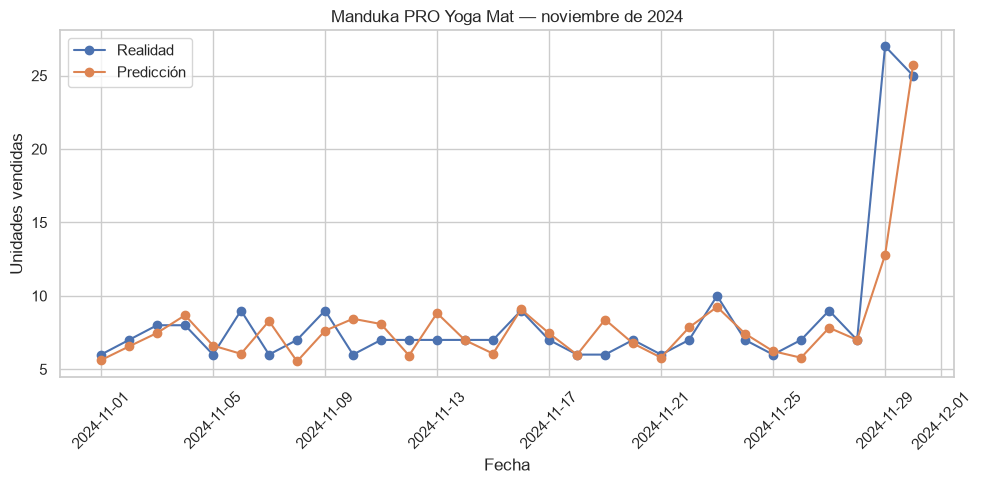

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

fechas = pd.to_datetime(ventas_df['fecha'], errors='coerce')
mascara_noviembre = (
    fechas.dt.year.eq(2024)
    & fechas.dt.month.eq(11)
    & ventas_df['es_estrella'].eq(True)
    & fechas.notna()
)

predicciones_noviembre = ventas_df.loc[mascara_noviembre].copy()
predicciones_noviembre['fecha'] = fechas.loc[mascara_noviembre]
predicciones_noviembre['unidades_predichas'] = modelo.predict(
    predicciones_noviembre[predictoras]
)

productos_estrella = predicciones_noviembre[
    ['producto_id', 'nombre']
].drop_duplicates(subset='producto_id')

if len(productos_estrella) != 7:
    raise ValueError(
        f'Se esperaban 7 productos estrella con datos en noviembre de 2024; '
        f'se encontraron {len(productos_estrella)}.'
    )

display(
    predicciones_noviembre[
        ['fecha', 'producto_id', 'nombre', 'unidades_vendidas', 'unidades_predichas']
    ].sort_values(['nombre', 'fecha'])
)

for _, producto in productos_estrella.iterrows():
    datos_diarios = (
        predicciones_noviembre[
            predicciones_noviembre['producto_id'].eq(producto['producto_id'])
        ]
        .groupby('fecha', as_index=False)[
            ['unidades_vendidas', 'unidades_predichas']
        ]
        .sum()
        .sort_values('fecha')
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        datos_diarios['fecha'],
        datos_diarios['unidades_vendidas'],
        marker='o',
        label='Realidad'
    )
    plt.plot(
        datos_diarios['fecha'],
        datos_diarios['unidades_predichas'],
        marker='o',
        label='Predicción'
    )
    plt.title(f"{producto['nombre']} — noviembre de 2024")
    plt.xlabel('Fecha')
    plt.ylabel('Unidades vendidas')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [28]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

fechas = pd.to_datetime(ventas_df['fecha'], errors='coerce')
mascara_2024 = (
    fechas.dt.year.eq(2024)
    & ventas_df['es_estrella'].eq(True)
    & fechas.notna()
    & ventas_df['unidades_vendidas'].notna()
)

datos_2024 = ventas_df.loc[mascara_2024].copy()
datos_2024['unidades_predichas'] = modelo.predict(datos_2024[predictoras])

mae_por_producto = (
    datos_2024
    .groupby(['producto_id', 'nombre'])
    .apply(
        lambda grupo: mean_absolute_error(
            grupo['unidades_vendidas'],
            grupo['unidades_predichas']
        ),
        include_groups=False
    )
    .rename('MAE')
    .reset_index()
    .sort_values('MAE')
)

display(mae_por_producto)

,producto_id,nombre,MAE
3,PROD_010,Domyos BM900,0.384000
2,PROD_009,Bowflex SelectTech 552,0.463529
5,PROD_016,Trek Marlin 7,0.506949
4,PROD_015,Salomon Speedcross 5 GTX,1.066502
6,PROD_021,Manduka PRO Yoga Mat,1.368830
1,PROD_002,Adidas Ultraboost 23,3.923205
0,PROD_001,Nike Air Zoom Pegasus 40,4.286432


,producto_id,nombre,periodo,dias_evaluados,MAE,sMAPE_pct,RMSE,WAPE_pct
3,PROD_002,Adidas Ultraboost 23,Días 1-10,10,2.920692,16.486547,3.570478,17.080068
4,PROD_002,Adidas Ultraboost 23,Días 11-20,10,4.956822,27.255222,5.766287,31.174979
5,PROD_002,Adidas Ultraboost 23,Días 21-30,10,3.892101,14.862662,5.466949,14.577157
6,PROD_009,Bowflex SelectTech 552,Días 1-10,10,0.565002,22.067578,0.586910,20.926002
7,PROD_009,Bowflex SelectTech 552,Días 11-20,10,0.437721,16.525281,0.487848,15.632905
8,PROD_009,Bowflex SelectTech 552,Días 21-30,10,0.387862,6.225083,0.696395,8.619167
9,PROD_010,Domyos BM900,Días 1-10,10,0.427898,16.073040,0.534618,14.263260
10,PROD_010,Domyos BM900,Días 11-20,10,0.398395,14.957274,0.503117,14.228407
11,PROD_010,Domyos BM900,Días 21-30,10,0.325707,9.050983,0.532684,6.929926
18,PROD_021,Manduka PRO Yoga Mat,Días 1-10,10,1.315689,18.262088,1.592804,18.273460


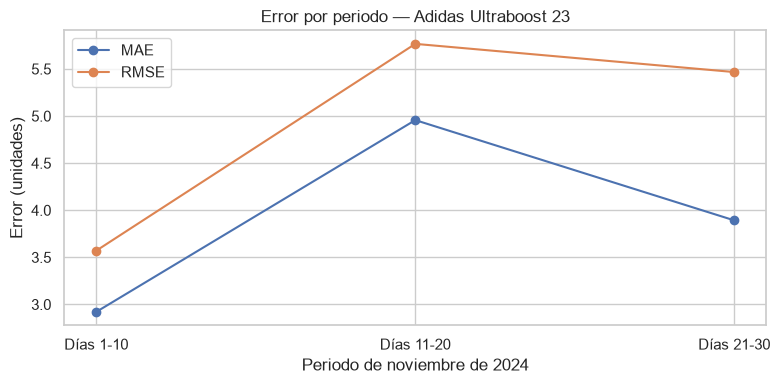

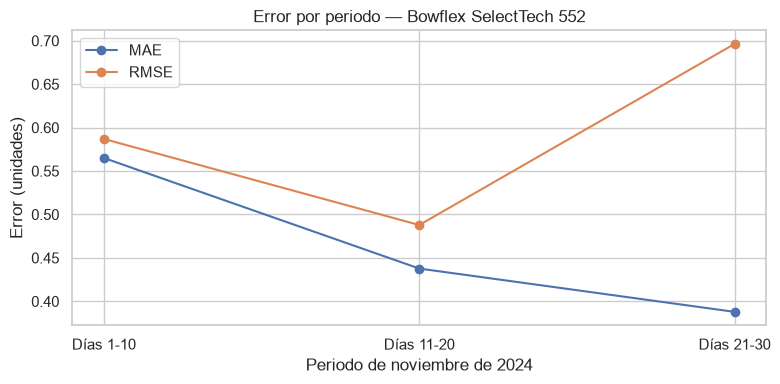

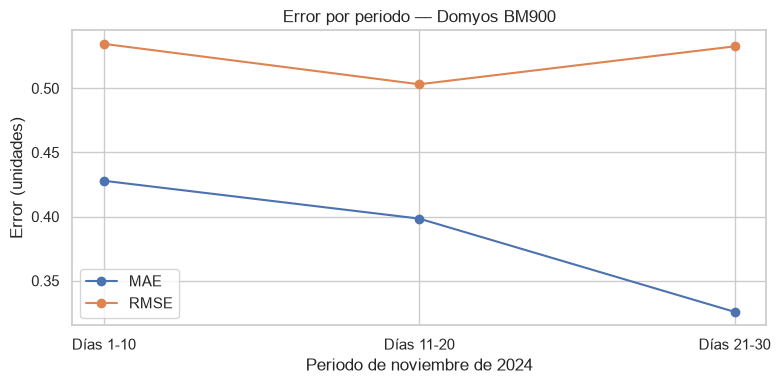

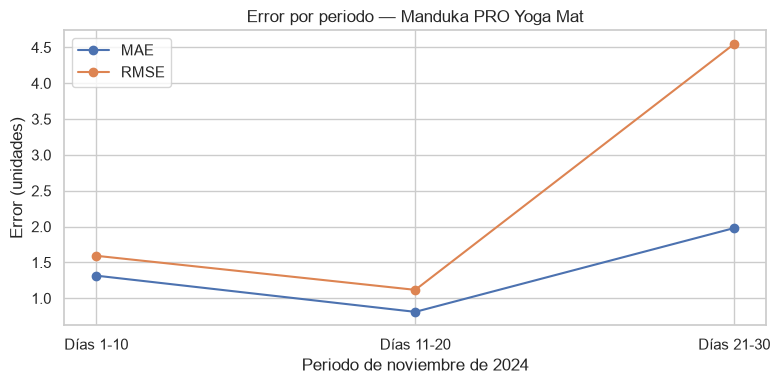

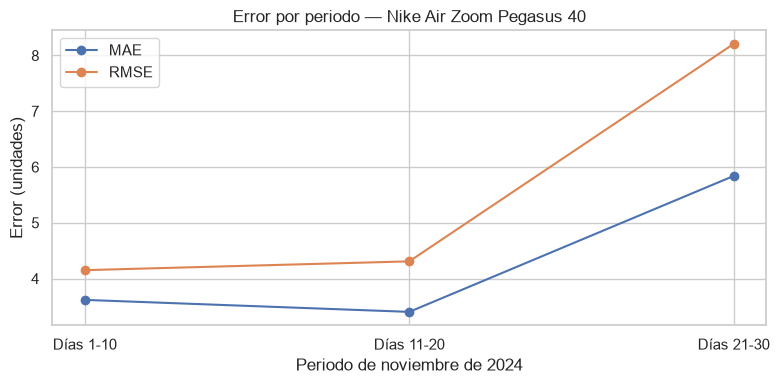

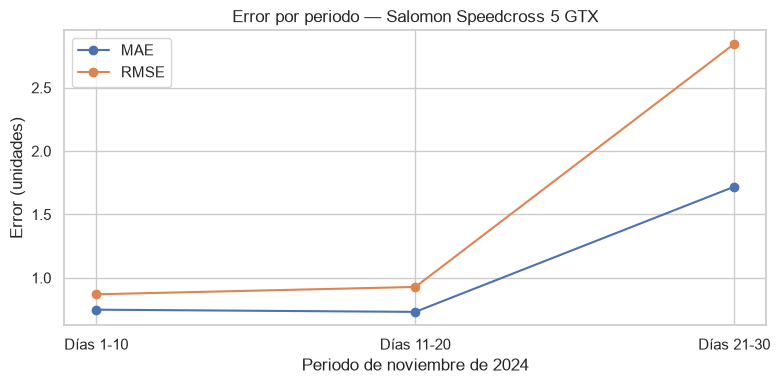

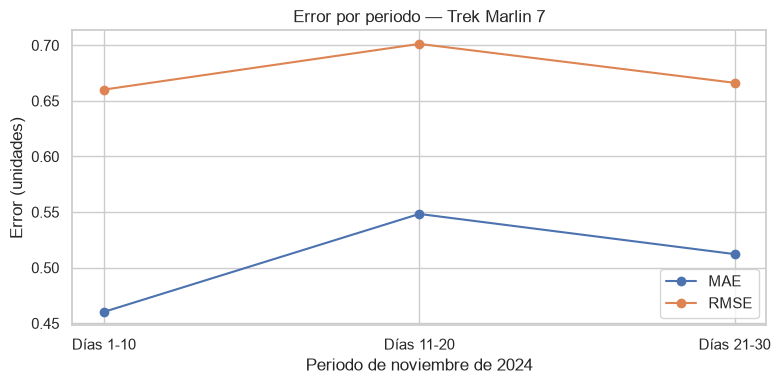

In [29]:

fechas = pd.to_datetime(ventas_df['fecha'], errors='coerce')
mascara = (
    fechas.dt.year.eq(2024)
    & fechas.dt.month.eq(11)
    & ventas_df['es_estrella'].eq(True)
    & ventas_df['unidades_vendidas'].notna()
    & fechas.notna()
)

noviembre_2024 = ventas_df.loc[mascara].copy()
noviembre_2024['fecha'] = fechas.loc[mascara]

if noviembre_2024.empty:
    raise ValueError('No hay datos de productos estrella en noviembre de 2024.')

periodos = ['Días 1-10', 'Días 11-20', 'Días 21-30']
noviembre_2024['periodo'] = pd.cut(
    noviembre_2024['fecha'].dt.day,
    bins=[0, 10, 20, 31],
    labels=periodos
)

noviembre_2024['unidades_predichas'] = modelo.predict(
    noviembre_2024[predictoras]
)

# Agrega los registros diarios antes de evaluar cada periodo.
diario = (
    noviembre_2024
    .groupby(
        ['producto_id', 'nombre', 'fecha', 'periodo'],
        observed=True,
        as_index=False
    )[['unidades_vendidas', 'unidades_predichas']]
    .sum()
)

diario['error_absoluto'] = (
    diario['unidades_vendidas'] - diario['unidades_predichas']
).abs()
diario['error_cuadrado'] = (
    diario['unidades_vendidas'] - diario['unidades_predichas']
) ** 2

denominador_smape = (
    diario['unidades_vendidas'].abs()
    + diario['unidades_predichas'].abs()
)
diario['smape_fila'] = np.divide(
    200 * diario['error_absoluto'],
    denominador_smape,
    out=np.zeros(len(diario), dtype=float),
    where=denominador_smape.to_numpy() != 0
)
diario['unidades_reales_abs'] = diario['unidades_vendidas'].abs()

metricas = (
    diario
    .groupby(['producto_id', 'nombre', 'periodo'], observed=True)
    .agg(
        dias_evaluados=('fecha', 'nunique'),
        MAE=('error_absoluto', 'mean'),
        MSE=('error_cuadrado', 'mean'),
        sMAPE_pct=('smape_fila', 'mean'),
        error_total=('error_absoluto', 'sum'),
        reales_abs_total=('unidades_reales_abs', 'sum')
    )
    .reset_index()
)

metricas['RMSE'] = np.sqrt(metricas['MSE'])
metricas['WAPE_pct'] = np.where(
    metricas['reales_abs_total'] != 0,
    100 * metricas['error_total'] / metricas['reales_abs_total'],
    np.nan
)
metricas = metricas.drop(
    columns=['MSE', 'error_total', 'reales_abs_total']
).sort_values(['nombre', 'periodo'])

display(metricas)

for _, producto in metricas[['producto_id', 'nombre']].drop_duplicates().iterrows():
    datos_producto = metricas[
        metricas['producto_id'].eq(producto['producto_id'])
    ].sort_values('periodo')

    plt.figure(figsize=(8, 4))
    plt.plot(datos_producto['periodo'].astype(str), datos_producto['MAE'],
             marker='o', label='MAE')
    plt.plot(datos_producto['periodo'].astype(str), datos_producto['RMSE'],
             marker='o', label='RMSE')
    plt.title(f"Error por periodo — {producto['nombre']}")
    plt.xlabel('Periodo de noviembre de 2024')
    plt.ylabel('Error (unidades)')
    plt.legend()
    plt.tight_layout()
    plt.show()

Productos evaluados: 24
MAE entre productos: 3.63
Sesgo promedio (predicción - realidad): -2.21


,producto_id,nombre,unidades_reales,unidades_predichas,error,error_absoluto
0,PROD_001,Nike Air Zoom Pegasus 40,66,52.787707,-13.212293,13.212293
1,PROD_002,Adidas Ultraboost 23,68,53.752192,-14.247808,14.247808
2,PROD_003,Asics Gel Nimbus 25,18,16.201483,-1.798517,1.798517
3,PROD_004,New Balance Fresh Foam X 1080v12,14,15.347729,1.347729,1.347729
4,PROD_005,Nike Dri-FIT Miler,14,16.847886,2.847886,2.847886
5,PROD_006,Adidas Own The Run Jacket,12,16.343632,4.343632,4.343632
6,PROD_007,Puma Velocity Nitro 2,13,10.298287,-2.701713,2.701713
7,PROD_008,Reebok Floatride Energy 5,12,16.301033,4.301033,4.301033
8,PROD_009,Bowflex SelectTech 552,10,11.988438,1.988438,1.988438
9,PROD_010,Domyos BM900,12,11.807847,-0.192153,0.192153


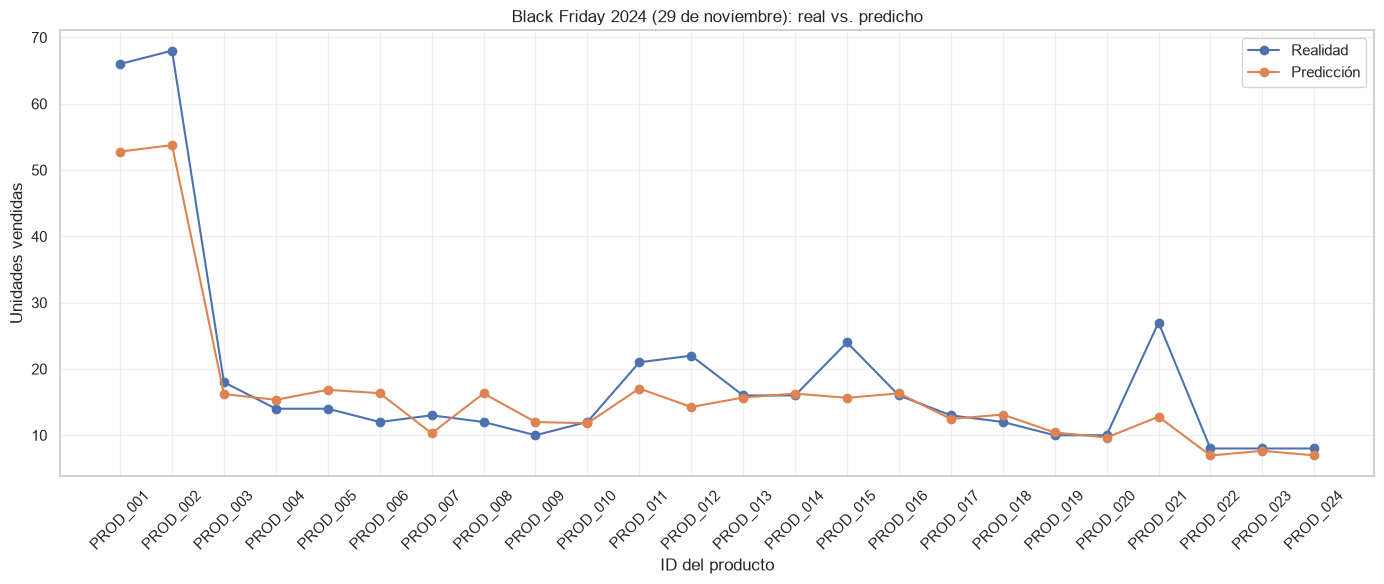

In [30]:


fechas = pd.to_datetime(ventas_df['fecha'], errors='coerce')
fecha_black_friday = pd.Timestamp('2024-11-29')

datos_bf = ventas_df.loc[
    fechas.dt.normalize().eq(fecha_black_friday)
    & ventas_df['unidades_vendidas'].notna()
].copy()

if datos_bf.empty:
    raise ValueError('No hay registros para Black Friday (29-11-2024).')

datos_bf['unidades_predichas'] = modelo.predict(datos_bf[predictoras])

resultados_bf = (
    datos_bf
    .groupby('producto_id', as_index=False)
    .agg(
        nombre=('nombre', 'first'),
        unidades_reales=('unidades_vendidas', 'sum'),
        unidades_predichas=('unidades_predichas', 'sum')
    )
    .sort_values('producto_id')
)

resultados_bf['error'] = (
    resultados_bf['unidades_predichas'] - resultados_bf['unidades_reales']
)
resultados_bf['error_absoluto'] = resultados_bf['error'].abs()

print(f'Productos evaluados: {len(resultados_bf)}')
print(f'MAE entre productos: {resultados_bf["error_absoluto"].mean():.2f}')
print(f'Sesgo promedio (predicción - realidad): {resultados_bf["error"].mean():.2f}')
display(resultados_bf)

posiciones = range(len(resultados_bf))

plt.figure(figsize=(14, 6))
plt.plot(
    posiciones,
    resultados_bf['unidades_reales'],
    marker='o',
    label='Realidad'
)
plt.plot(
    posiciones,
    resultados_bf['unidades_predichas'],
    marker='o',
    label='Predicción'
)
plt.xticks(posiciones, resultados_bf['producto_id'].astype(str), rotation=45)
plt.xlabel('ID del producto')
plt.ylabel('Unidades vendidas')
plt.title('Black Friday 2024 (29 de noviembre): real vs. predicho')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

fechas_modelo = pd.to_datetime(ventas_df['fecha'], errors='coerce')

mascara_historica = (
    fechas_modelo.dt.year.between(2021, 2024)
    & ventas_df['unidades_vendidas'].notna()
)

datos_finales = ventas_df.loc[mascara_historica].copy()

X_final = datos_finales[predictoras]
y_final = datos_finales['unidades_vendidas']

modelo_final = HistGradientBoostingRegressor(
    learning_rate=0.03,
    max_iter=500,
    max_depth=5,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

modelo_final.fit(X_final, y_final)

print(f'Registros usados para el entrenamiento final: {len(datos_finales)}')
print(f'Número de predictoras: {len(predictoras)}')
print('Modelo final entrenado: modelo_final')

Registros usados para el entrenamiento final: 2880
Número de predictoras: 12
Modelo final entrenado: modelo_final


,variable,importancia_media,desviacion_std
0,descuento_porcentaje,1.770681,0.034033
1,unidades_vendidas_lag_1,1.120501,0.020721
2,unidades_vendidas_lag_7,0.852532,0.022034
3,media_movil_7_dias,0.435129,0.010780
4,unidades_vendidas_lag_6,0.185054,0.008545
5,unidades_vendidas_lag_4,0.105117,0.005300
6,unidades_vendidas_lag_2,0.078008,0.004212
7,unidades_vendidas_lag_3,0.066191,0.004528
8,precio_venta,0.036055,0.003147
9,unidades_vendidas_lag_5,0.021105,0.002714


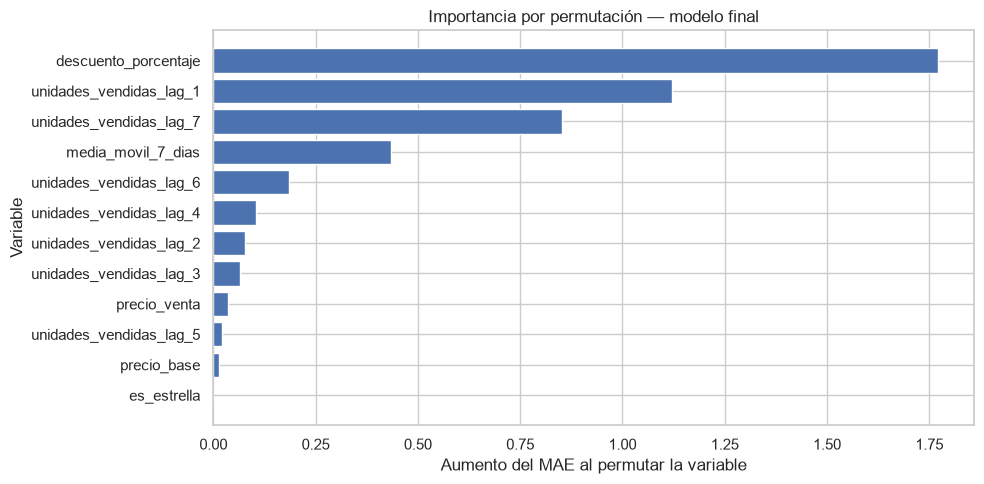

Modelo guardado en: models\modelo_final.joblib


In [32]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

importancia = permutation_importance(
    modelo_final,
    X_final,
    y_final,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importancias_df = (
    pd.DataFrame({
        'variable': X_final.columns,
        'importancia_media': importancia.importances_mean,
        'desviacion_std': importancia.importances_std
    })
    .sort_values('importancia_media', ascending=False)
    .reset_index(drop=True)
)

display(importancias_df)

# barh dibuja desde abajo hacia arriba; invertir el orden deja la mayor arriba.
grafico_df = importancias_df.sort_values('importancia_media', ascending=True)

plt.figure(figsize=(10, max(5, 0.4 * len(grafico_df))))
plt.barh(grafico_df['variable'], grafico_df['importancia_media'])
plt.xlabel('Aumento del MAE al permutar la variable')
plt.ylabel('Variable')
plt.title('Importancia por permutación — modelo final')
plt.tight_layout()
plt.show()

os.makedirs('models', exist_ok=True)
joblib.dump(modelo_final, r'models\modelo_final.joblib')
print('Modelo guardado en: models\\modelo_final.joblib')

In [35]:
competencia_df.columns

Index(['fecha', 'producto_id', 'Amazon', 'Decathlon', 'Deporvillage'],
      dtype='str')